<a href="https://colab.research.google.com/github/europecodingschool/ECS---VB---YZ---08.26/blob/main/VB_YZ_Ders_25_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
!pip install -q mediapipe # mediapipe kurulu gelmediği için kurduk.

In [7]:
import cv2
import matplotlib.pyplot as plt
import urllib.request
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

In [13]:
#Modelimizi ve Örnek Fotoğrafları Çağırdık
model_adresi = ("https://storage.googleapis.com/mediapipe-models/image_classifier/efficientnet_lite0/float32/latest/efficientnet_lite0.tflite") # modelimizin url i.
urllib.request.urlretrieve(model_adresi, "efficientnet_lite0.tflite") # modeli çekip kaydedicez.
#

foto_adresi = "https://storage.googleapis.com/mediapipe-tasks/image_classifier/"
urllib.request.urlretrieve(foto_adresi + "burger.jpg", "burger.jpg")
urllib.request.urlretrieve(foto_adresi + "cat.jpg", "kedi.jpg")
#
print("Mediapipe Sürümü:", mp.__version__)

Mediapipe Sürümü: 1.2.3


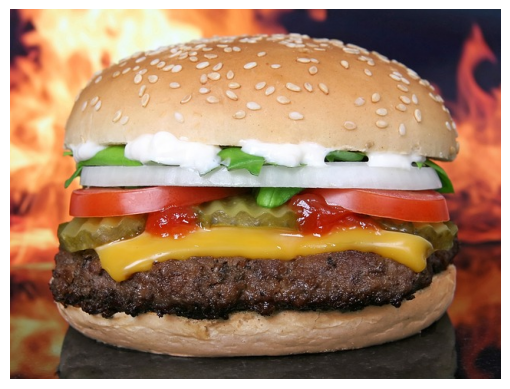

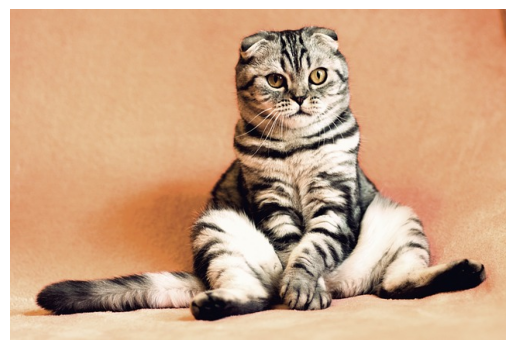

In [16]:
#Fotoğraflara Bakalım

burger = cv2.imread("burger.jpg")
burger = cv2.cvtColor(burger, cv2.COLOR_BGR2RGB)
plt.imshow(burger)
plt.axis("off")
plt.show()

kedi = cv2.imread("kedi.jpg")
kedi = cv2.cvtColor(kedi, cv2.COLOR_BGR2RGB)
plt.imshow(kedi)
plt.axis("off")
plt.show()
#

In [19]:
print("Burger:", burger.shape)
print("Kedi:", kedi.shape)

Burger: (482, 640, 3)
Kedi: (427, 640, 3)


MEDIAPIPE ÇALIŞMA PRENSİBİ:

1- Temel Ayarlar - Hangi Model
2- Göreve Özel Araçlar(kaç sonuç)
3- Görevi Oluşturma

In [23]:
#Sınıflandırıcı Kurmak

temel_ayarlar = python.BaseOptions(model_asset_path = "efficientnet_lite0.tflite") # yukarıda çağırdığımız modeli burada kullanıyoruz.
ayarlar = vision.ImageClassifierOptions(base_options=temel_ayarlar, max_results=3) # max_result modelde 1000 sınıf var. En yüksek 3 ü göster.
siniflandirici = vision.ImageClassifier.create_from_options(ayarlar)

print("Sınıflandırıcı Hazır:", type(siniflandirici).__name__)



Sınıflandırıcı Hazır: ImageClassifier


In [25]:
# Bir fotoğrafı sınıflandırmak. # Mediapipe fotoğrafları RGB sırasında ve kendi mp.Image biçiminde ister. Önce bu dönüşümleri yapacağız. Sonra Modele vereceğiz.

burger_rgb = cv2.cvtColor(burger, cv2.COLOR_BGR2RGB)
mp.goruntu = mp.Image(image_format=mp.ImageFormat.SRGB, data=burger_rgb)

sonuc = siniflandirici.classify(mp.goruntu)

tahminler = sonuc.classifications[0].categories
for tahmin in tahminler:
  print(tahmin.index, tahmin.category_name, tahmin.score)
#
#


933 cheeseburger 0.9416055083274841
931 bagel 0.007148840464651585
947 mushroom 0.004316502250730991


In [26]:
kedi_rgb = cv2.cvtColor(kedi, cv2.COLOR_BGR2RGB)
mp.goruntu = mp.Image(image_format=mp.ImageFormat.SRGB, data=kedi_rgb)

sonuc = siniflandirici.classify(mp.goruntu)

tahminler = sonuc.classifications[0].categories
for tahmin in tahminler:
  print(tahmin.index, tahmin.category_name, tahmin.score)
#

282 tiger cat 0.3009193241596222
281 tabby 0.18437938392162323
292 tiger 0.15057247877120972
